In [ ]:
import pandas as pd
import numpy as np
import pickle
import csv
import matplotlib.pyplot as plt  
import seaborn as sns  
import datetime as dt  
import re  
import string  
import nltk  
import requests
nltk.download('punkt_tab')  
nltk.download('stopwords')  
from nltk.tokenize import word_tokenize  
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from nltk.corpus import stopwords  
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory  
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory  
from wordcloud import WordCloud  
from sklearn.metrics import accuracy_score
from gensim.models import Word2Vec
from sklearn.svm import SVC
from io import StringIO
seed = 0
np.random.seed(seed)  

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\asus\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\asus\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Loading Dataset

In [6]:
df_review = pd.read_csv('scrapped_data_stockbit.csv')
df_review = df_review.copy()
print("Jumlah baris beserta kolom:", df_review.shape)

Jumlah baris beserta kolom: (10000, 11)


Memahami Struktur Data

In [7]:
df_review.head()

,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,a8383c39-2ed9-4fef-951a-56eccc6c571b,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Dr semua aplikasi paling enak stockbit tp seme...,1,22,3.15.2,2025-09-24 21:29:41,"Halo Kak Angeline Kodekarja,\n\nMohon maaf ata...",2025-09-25 10:59:31,3.15.2
1,2afee930-84b5-4a2f-b9e2-8a83310427d5,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Stockbit benar-benar aplikasi investasi terbai...,5,4,3.15.2,2025-10-15 17:24:37,"Halo kak Ilmi Nihgenk,\n\nKami senang sekali k...",2025-10-16 11:33:43,3.15.2
2,77bc8b5b-79f6-41b4-8b93-e4213bb06473,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,untuk verifkasi trusted device tolong ditambah...,5,28,3.15.3,2025-10-01 00:09:14,"Halo Kak Mbah Tutor,\n\nTerima kasih atas upda...",2025-10-02 17:13:24,3.15.3
3,2f42015d-8632-4311-a475-422ddbe87a77,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"aku uninstall untuk terakhir kali, kita pisah,...",1,13,3.15.1,2025-10-01 12:51:52,"Halo FACHRUR ROZI AMRIL MUTTAQIN,\n\nMohon maa...",2025-10-03 11:06:35,3.15.1
4,7e391a2e-8032-45a0-b671-5c047d370e88,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,ini sekuritas paling keren !! user friendly sa...,5,37,3.15.2,2025-09-29 13:13:12,"Halo kak DA Fi,\n\nSenang sekali baca review p...",2025-09-29 17:19:42,3.15.2


In [8]:
print(df_review.info())
print(df_review.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   reviewId              10000 non-null  object
 1   userName              10000 non-null  object
 2   userImage             10000 non-null  object
 3   content               10000 non-null  object
 4   score                 10000 non-null  int64 
 5   thumbsUpCount         10000 non-null  int64 
 6   reviewCreatedVersion  8553 non-null   object
 7   at                    10000 non-null  object
 8   replyContent          8655 non-null   object
 9   repliedAt             8655 non-null   object
 10  appVersion            8553 non-null   object
dtypes: int64(2), object(9)
memory usage: 859.5+ KB
None
              score  thumbsUpCount
count  10000.000000   10000.000000
mean       3.698000       2.505200
std        1.677044      12.978521
min        1.000000       0.000000
25%       

Cleaning and Preprocessing

In [9]:
print("Jumlah nilai null per kolom:")
print(df_review.isnull().sum())

# Cek jumlah baris yang duplikat
print("\nJumlah baris duplikat:")
print(df_review.duplicated().sum())

Jumlah nilai null per kolom:
reviewId                   0
userName                   0
userImage                  0
content                    0
score                      0
thumbsUpCount              0
reviewCreatedVersion    1447
at                         0
replyContent            1345
repliedAt               1345
appVersion              1447
dtype: int64

Jumlah baris duplikat:
0


In [10]:
df_cleaned = df_review.dropna(subset=['content', 'score', 'at', 'thumbsUpCount'])
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   reviewId              10000 non-null  object
 1   userName              10000 non-null  object
 2   userImage             10000 non-null  object
 3   content               10000 non-null  object
 4   score                 10000 non-null  int64 
 5   thumbsUpCount         10000 non-null  int64 
 6   reviewCreatedVersion  8553 non-null   object
 7   at                    10000 non-null  object
 8   replyContent          8655 non-null   object
 9   repliedAt             8655 non-null   object
 10  appVersion            8553 non-null   object
dtypes: int64(2), object(9)
memory usage: 859.5+ KB


In [11]:
datetime_columns = ["at"]

for column in datetime_columns:
  df_cleaned[column] = pd.to_datetime(df_cleaned[column])

In [ ]:
new_df = df_cleaned[['userName', 'score','at', 'content', 'thumbsUpCount']]
new_df = new_df.sort_values(by='at', ascending=False) 
new_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 8989 to 3448
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   userName       10000 non-null  object        
 1   score          10000 non-null  int64         
 2   at             10000 non-null  datetime64[ns]
 3   content        10000 non-null  object        
 4   thumbsUpCount  10000 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 468.8+ KB


In [ ]:
def cleaningText(text):
    text = re.sub(r'@[A-Za-z0-9]+', '', text) 
    text = re.sub(r'#[A-Za-z0-9]+', '', text) 
    text = re.sub(r'RT[\s]', '', text) 
    text = re.sub(r"http\S+", '', text) 
    text = re.sub(r'[0-9]+', '', text) 
    text = re.sub(r'[^\w\s]', '', text) 
 
    text = text.replace('\n', ' ') 
    text = text.translate(str.maketrans('', '', string.punctuation)) 
    text = text.strip(' ') 
    return text
 
def casefoldingText(text): 
    text = text.lower()
    return text
 
def tokenizingText(text): 
    text = word_tokenize(text)
    return text
 
def filteringText(text): 
    listStopwords = set(stopwords.words('indonesian'))
    listStopwords1 = set(stopwords.words('english'))
    listStopwords.update(listStopwords1)
    listStopwords.update(['saham', 'emiten', 'idx', 'ihsg', 'reksadana', 'rupiah', 'rp'])
    filtered = []
    for txt in text:
        if txt not in listStopwords:
            filtered.append(txt)
    text = filtered
    return text
 
def stemmingText(text): 
    
    factory = StemmerFactory()
    stemmer = factory.create_stemmer()
 
    
    words = text.split()
 
    
    stemmed_words = [stemmer.stem(word) for word in words]
 
    
    stemmed_text = ' '.join(stemmed_words)
 
    return stemmed_text
 
def toSentence(list_words): 
    sentence = ' '.join(word for word in list_words)
    return sentence

In [ ]:
slangwords = {
    
    "cuan": "untung",
    "boncos": "rugi",
    "sangkut": "tersangkut",
    "nyangkut": "tersangkut",
    "haka": "beli",
    "hajar kanan": "beli",
    "bandar": "bandar", 
    "arb": "auto reject bawah",
    "ara": "auto reject atas",
    "mantul": "mantap",
    "rekom": "rekomendasi",
    "pom pom": "promosi",
    "porto": "portofolio",

    
}
def fix_slangwords(text):
    words = text.split()
    fixed_words = []
 
    for word in words:
        if word.lower() in slangwords:
            fixed_words.append(slangwords[word.lower()])
        else:
            fixed_words.append(word)
 
    fixed_text = ' '.join(fixed_words)
    return fixed_text

In [ ]:

new_df['text_clean'] = new_df['content'].apply(cleaningText)
 

new_df['text_casefoldingText'] = new_df['text_clean'].apply(casefoldingText)
 

new_df['text_slangwords'] = new_df['text_casefoldingText'].apply(fix_slangwords)
 

new_df['text_tokenizingText'] = new_df['text_slangwords'].apply(tokenizingText)
 

new_df['text_stopword'] = new_df['text_tokenizingText'].apply(filteringText)
 

new_df['text_akhir'] = new_df['text_stopword'].apply(toSentence)

Labeling

In [ ]:

lexicon_positive = dict()
 
response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv')

 
if response.status_code == 200:
    
    reader = csv.reader(StringIO(response.text), delimiter=',')
    
 
    for row in reader:
        
        lexicon_positive[row[0]] = int(row[1])
        
else:
    print("Failed to fetch positive lexicon data")
 

lexicon_negative = dict()
 
response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv')

 
if response.status_code == 200:
    
    reader = csv.reader(StringIO(response.text), delimiter=',')
    
 
    for row in reader:
        
        lexicon_negative[row[0]] = int(row[1])
        
else:
    print("Failed to fetch negative lexicon data")

In [ ]:

 
def sentiment_analysis_lexicon_indonesia(text):
    
 
    score = 0
    
 
    for word in text:
        
 
        if (word in lexicon_positive):
            score = score + lexicon_positive[word]
            
 
    for word in text:
        
 
        if (word in lexicon_negative):
            score = score + lexicon_negative[word]
            
 
    polarity=''
    
 
    if (score >= 0):
        polarity = 'positive'
        
    elif (score < 0):
        polarity = 'negative'
        
 
    
    
    
 
    return score, polarity
    

In [19]:
results = new_df['text_stopword'].apply(sentiment_analysis_lexicon_indonesia)
results = list(zip(*results))
new_df['polarity_score'] = results[0]
new_df['polarity'] = results[1]
print(new_df['polarity'].value_counts())

polarity
positive    6253
negative    3747
Name: count, dtype: int64


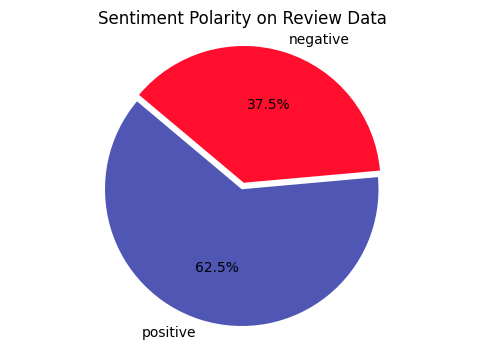

In [32]:
sentiment_counts = new_df['polarity'].value_counts()

labels = sentiment_counts.index
sizes = sentiment_counts.values
colors = ["#4f56b4", "#ff0e2e"]
explode = (0.05, 0) if 'negative' in labels and 'positive' in labels else (0, 0)

plt.figure(figsize=(6, 4))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, explode=explode)
plt.title('Sentiment Polarity on Review Data')
plt.axis('equal')
plt.show()


Eksplorasi Label

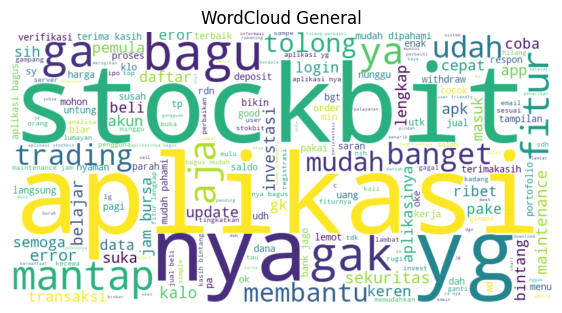

In [22]:
all_words = ' '.join([' '.join(tokens) for tokens in new_df['text_stopword']])

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_words)

plt.figure(figsize=(7, 4))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud General')
plt.show()


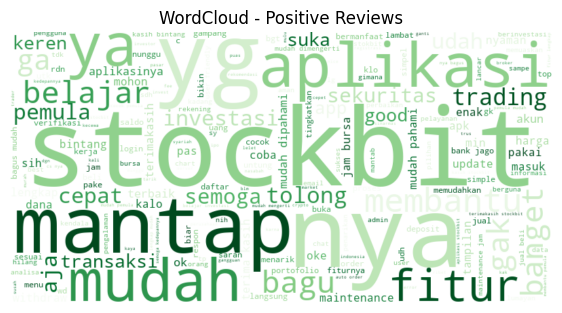

In [23]:
positive_words = ' '.join([' '.join(tokens) for tokens in new_df[new_df['polarity'] == 'positive']['text_stopword']])

wordcloud_pos = WordCloud(width=800, height=400, background_color='white', colormap='Greens').generate(positive_words)

plt.figure(figsize=(7, 4))
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud - Positive Reviews')
plt.show()

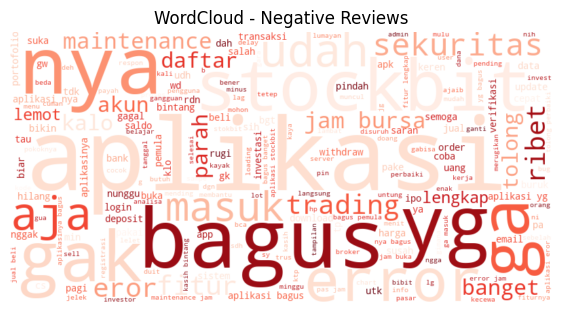

In [25]:
negative_words = ' '.join([' '.join(tokens) for tokens in new_df[new_df['polarity'] == 'negative']['text_stopword']])

wordcloud_neg = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate(negative_words)

plt.figure(figsize=(7, 4))
plt.imshow(wordcloud_neg, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud - Negative Reviews')
plt.show()


Modeling dan Ekstraksi fitur

In [26]:
tfidf = TfidfVectorizer(max_features=1000, min_df=2, max_df=0.95, ngram_range=(1,2))
X_tfidf = tfidf.fit_transform(new_df['text_akhir'])
y = new_df['polarity']
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.3, random_state=42)

model_rf = RandomForestClassifier(n_estimators=200, random_state=42)
model_rf.fit(X_train, y_train)
y_pred_train = model_rf.predict(X_train)
y_pred_test = model_rf.predict(X_test)

print("RF TF-IDF - accuracy train:", accuracy_score(y_train, y_pred_train))
print("RF TF-IDF - accuracy test :", accuracy_score(y_test, y_pred_test))


RF TF-IDF - accuracy train: 0.9944285714285714
RF TF-IDF - accuracy test : 0.87


In [ ]:
X = new_df['text_akhir']
y = new_df['polarity']

tfidf_svm = TfidfVectorizer(max_features=1000, min_df=2, max_df=0.95, ngram_range=(1,2))
X_tfidf_svm = tfidf_svm.fit_transform(X)


X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(X_tfidf_svm, y, test_size=0.2, random_state=42)

svm_model = SVC()
svm_model.fit(X_train_svm, y_train_svm)

y_pred_train_svm = svm_model.predict(X_train_svm)
y_pred_test_svm = svm_model.predict(X_test_svm)

print("SVM TF-IDF - accuracy train:", accuracy_score(y_pred_train_svm, y_train_svm))
print("SVM TF-IDF - accuracy test:", accuracy_score(y_pred_test_svm, y_test_svm))

SVM TF-IDF - accuracy train: 0.981625
SVM TF-IDF - accuracy test: 0.897


In [28]:
model_w2v = Word2Vec(sentences=new_df['text_stopword'], vector_size=100, window=5, min_count=2, workers=4)

def sentence_vector(tokens):
    vectors = [model_w2v.wv[word] for word in tokens if word in model_w2v.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(100)

X_w2v = np.array([sentence_vector(tokens) for tokens in new_df['text_stopword']])

# Split 80/20
X_train_rf2, X_test_rf2, y_train_rf2, y_test_rf2 = train_test_split(X_w2v, y, test_size=0.2, random_state=42)

rf_model2 = RandomForestClassifier()
rf_model2.fit(X_train_rf2, y_train_rf2)

y_pred_train_rf2 = rf_model2.predict(X_train_rf2)
y_pred_test_rf2 = rf_model2.predict(X_test_rf2)

print("RF Word2Vec - accuracy train:", accuracy_score(y_pred_train_rf2, y_train_rf2))
print("RF Word2Vec - accuracy test:", accuracy_score(y_pred_test_rf2, y_test_rf2))


RF Word2Vec - accuracy train: 0.9995
RF Word2Vec - accuracy test: 0.72


Model SVM dengan ekstraksi fitur TF-IDF merupakan model terbaik dibandingkan kedua model yang lain karena memiliki akurasi tinggi dan perbedaan antara training dan test tidak besar. Model ini sangat cocok dengan data hasil TF-IDF karena menangani data berdimensi tinggi dengan baik.

In [29]:
with open('model_svm_stockbit.pkl', 'wb') as f:
    pickle.dump(svm_model, f)
with open('tfidf_vectorizer_stockbit.pkl', 'wb') as f:
    pickle.dump(tfidf_svm, f)